# Activity 6.06 — Creating a Scatter Plot with Marginal Histograms

**Student:** LU MENGJIE (MC643920)  
**Purpose:** Filter AnAge to birds (Aves) with body mass under 20,000 g; show their body-mass/longevity scatter and marginal distributions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from pathlib import Path

def locate_datasets():
    here = Path.cwd().resolve()
    for folder in (here, *here.parents):
        candidate = folder / "Datasets"
        if candidate.is_dir():
            return candidate
    raise FileNotFoundError("Could not find the project Datasets folder.")

DATASETS = locate_datasets()
print("Datasets:", DATASETS)

Datasets: C:\Users\22392\Desktop\cisc7204_sugex06_mc643920\Submission\cisc7204_sugex06_MC643920\Datasets


In [2]:
animals = pd.read_csv(DATASETS / 'anage_data.csv', index_col=0)
aves = animals.loc[animals['Class'] == 'Aves', ['Body mass (g)', 'Maximum longevity (yrs)']].copy()
aves = aves.replace([np.inf, -np.inf], np.nan).dropna()
aves = aves[(aves['Body mass (g)'] > 0) & (aves['Body mass (g)'] < 20000) & (aves['Maximum longevity (yrs)'] > 0)]
print(f'Bird records after filtering: {len(aves)}')
aves.head()

Bird records after filtering: 166


,Body mass (g),Maximum longevity (yrs)
184,135.0,20.2
189,3000.0,48.0
199,658.0,22.4
214,2860.0,42.0
232,652.0,29.0


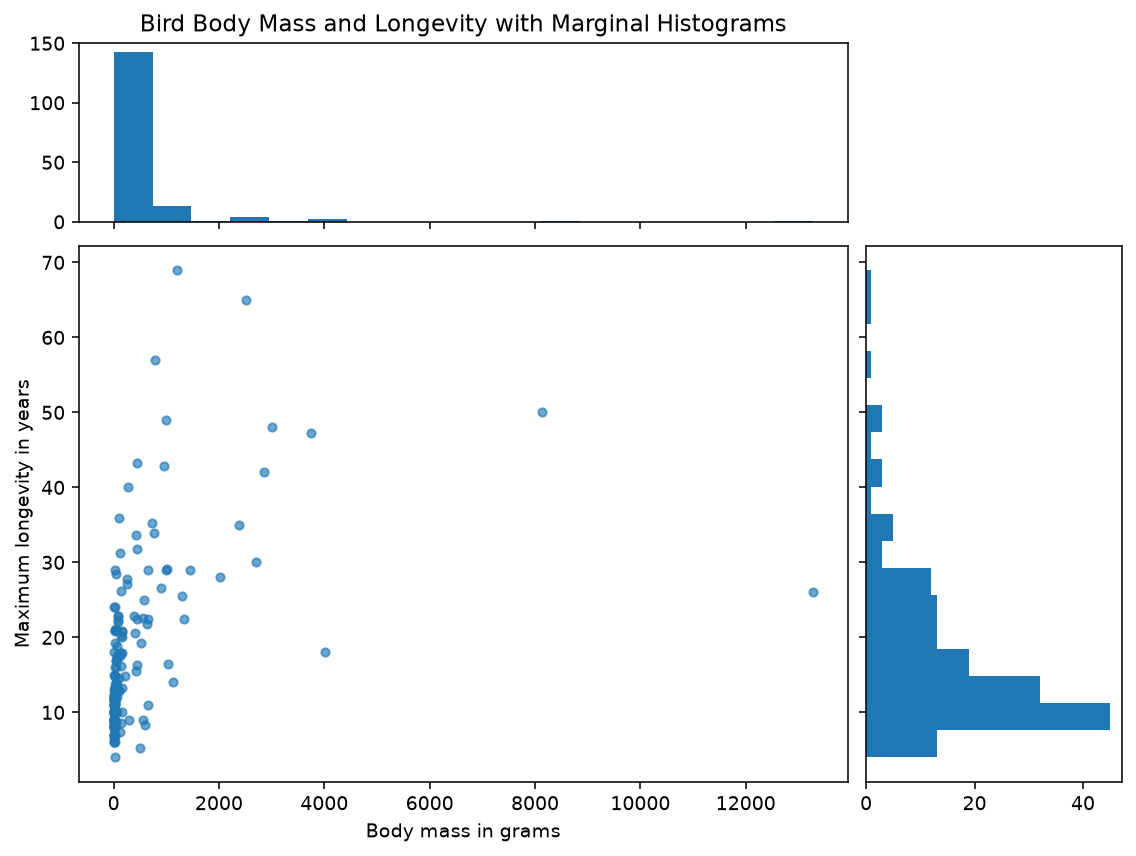

In [3]:
fig = plt.figure(figsize=(8, 6), dpi=140, constrained_layout=True)
gs = fig.add_gridspec(4, 4)
ax_scatter = fig.add_subplot(gs[1:, :-1])
ax_histx = fig.add_subplot(gs[0, :-1], sharex=ax_scatter)
ax_histy = fig.add_subplot(gs[1:, -1], sharey=ax_scatter)
ax_scatter.scatter(aves['Body mass (g)'], aves['Maximum longevity (yrs)'], s=18, alpha=0.65)
ax_histx.hist(aves['Body mass (g)'], bins=18)
ax_histy.hist(aves['Maximum longevity (yrs)'], bins=18, orientation='horizontal')
ax_scatter.set_xlabel('Body mass in grams')
ax_scatter.set_ylabel('Maximum longevity in years')
ax_histx.set_title('Bird Body Mass and Longevity with Marginal Histograms')
ax_histx.tick_params(labelbottom=False)
ax_histy.tick_params(labelleft=False)
plt.show()